# CSC261 – Project 1: Used-Car Price & Transmission Prediction

**King Saud University — College of Computer and Information Sciences, Computer Science Department**

This notebook contains all the code for the project:

| Part | Task | Model |
|---|---|---|
| **Part 1** | Predict a used car's **selling price** (continuous) | Linear Regression + K-Fold Cross-Validation |
| **Part 2** | Predict whether a car is **Automatic or Manual** (binary) | Logistic Regression |

Dataset: `data/car_data.csv` — 301 used-vehicle listings, 9 columns.
Prices (`Selling_Price`, `Present_Price`) are in **lakhs of Indian rupees** (1 lakh = ₹100,000).

Every figure is saved to the `figures/` folder so it can be reused in the report.

## 0. Setup — imports and plot style

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, accuracy_score, precision_score,
                             recall_score, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)

RANDOM_STATE = 1                      # required by the project brief
DATA_PATH = Path("data/car_data.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

In [2]:
# ---- Plot style: thin marks, light grid, colour-blind-safe palette ----
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
LIGHT_BLUE = "#b7d3f6"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 9,
})
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", RED])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#eef5fe", "#86b6ef", "#2a78d6", "#104281"])
plain_numbers = FuncFormatter(lambda v, _: f"{v:g}")

def save(fig, name):
    """Save a figure into figures/ and show it."""
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 1. Load the data

In [3]:
df_raw = pd.read_csv(DATA_PATH)
df_raw.head(10)

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
5,vitara brezza,2018,9.25,9.83,2071,Diesel,Dealer,Manual,0
6,ciaz,2015,6.75,8.12,18796,Petrol,Dealer,Manual,0
7,s cross,2015,6.50,8.61,33429,Diesel,Dealer,Manual,0
8,ciaz,2016,8.75,8.89,20273,Diesel,Dealer,Manual,0
9,ciaz,2015,7.45,8.92,42367,Diesel,Dealer,Manual,0


In [4]:
print("Shape (rows, columns):", df_raw.shape)

Shape (rows, columns): (301, 9)


In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [6]:
df_raw.describe().round(3)

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000,301.000,301.000,301.000,301.000
mean,2013.628,4.661,7.628,36947.206,0.043
std,2.892,5.083,8.644,38886.884,0.248
min,2003.000,0.100,0.320,500.000,0.000
25%,2012.000,0.900,1.200,15000.000,0.000
50%,2014.000,3.600,6.400,32000.000,0.000
75%,2016.000,6.000,9.900,48767.000,0.000
max,2018.000,35.000,92.600,500000.000,3.000


In [7]:
# Categorical columns: what values do they take?
for col in ["Car_Name", "Fuel_Type", "Seller_Type", "Transmission", "Owner"]:
    vc = df_raw[col].value_counts()
    print(f"{col}: {df_raw[col].nunique()} unique values")
    if col != "Car_Name":
        print(vc.to_string(), "\n")
print("Top car names:\n", df_raw["Car_Name"].value_counts().head(8).to_string())

Car_Name: 98 unique values
Fuel_Type: 3 unique values
Fuel_Type
Petrol    239
Diesel     60
CNG         2 

Seller_Type: 2 unique values
Seller_Type
Dealer        195
Individual    106 

Transmission: 2 unique values
Transmission
Manual       261
Automatic     40 

Owner: 3 unique values
Owner
0    290
1     10
3      1 

Top car names:
 Car_Name
city             26
corolla altis    16
verna            14
fortuner         11
brio             10
ciaz              9
innova            9
i20               9


In [8]:
# Data-quality checks: missing values and exact duplicate rows
print("Missing values per column:\n", df_raw.isna().sum().to_string(), "\n")
dups = df_raw[df_raw.duplicated(keep=False)]
print(f"Exact duplicate rows: {df_raw.duplicated().sum()}")
dups

Missing values per column:
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0 

Exact duplicate rows: 2


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


In [9]:
# Drop exact duplicates so the same listing cannot appear in both the
# training set and the test set (that would make the test score look better than it is).
df = df_raw.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (299, 9)


**Observations.**
* No missing values in any column, and the data types are sensible (5 numeric, 4 text columns).
* 2 rows are exact duplicates (an Ertiga and a Fortuner listed twice). We remove them, leaving **299 rows**.
* `Car_Name` has 98 different values, so it is too fine-grained to use directly.
* The "car" dataset also contains **about 100 motorcycles and scooters** (Royal Enfield, Bajaj Pulsar, Honda Activa, …), almost all sold by individuals. This is why so many prices are below 2 lakh.

---
# Part 1 — Predicting Selling Price with Linear Regression

**Problem statement.** Given a used vehicle's characteristics (original showroom price, age,
kilometres driven, fuel type, seller type, transmission and number of previous owners),
estimate the price it will sell for. Target **y = `Selling_Price`** (continuous, lakhs ₹).

## 2. Exploratory Data Analysis (EDA)

### 2.1 Distribution of prices

Selling_Price: mean=4.59, median=3.51, skew=2.54
Present_Price: mean=7.54, median=6.10, skew=4.19


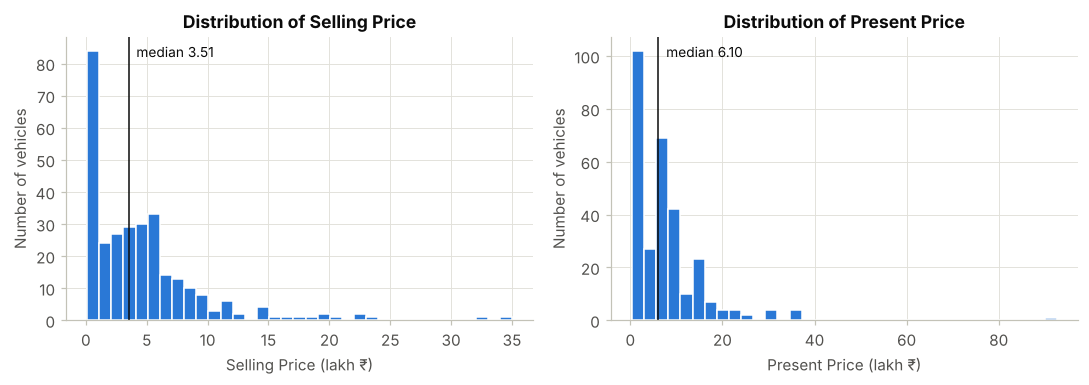

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col in zip(axes, ["Selling_Price", "Present_Price"]):
    ax.hist(df[col], bins=35, color=BLUE, edgecolor="white", linewidth=1)
    med, mean = df[col].median(), df[col].mean()
    ax.axvline(med, color=INK, linewidth=1)
    ax.text(med, ax.get_ylim()[1] * 0.93, f"  median {med:.2f}", color=INK, fontsize=9)
    ax.set_title(f"Distribution of {col.replace('_', ' ')}")
    ax.set_xlabel(f"{col.replace('_', ' ')} (lakh ₹)"); ax.set_ylabel("Number of vehicles")
    print(f"{col}: mean={mean:.2f}, median={med:.2f}, skew={df[col].skew():.2f}")
fig.tight_layout()
save(fig, "fig01_price_histograms")

**Interpretation.** Both prices are strongly **right-skewed** (skewness 2.5 and 4.2). Most vehicles cost under 10 lakh, with a large spike below 1 lakh (the two-wheelers) and a long tail of expensive SUVs (Fortuner; Land Cruiser at 92.6 lakh new). The mean selling price (4.59) is above the median (3.51) because of that tail. A few extreme vehicles will have a large influence on a least-squares model, since squared errors punish them heavily.

### 2.2 Present price vs selling price

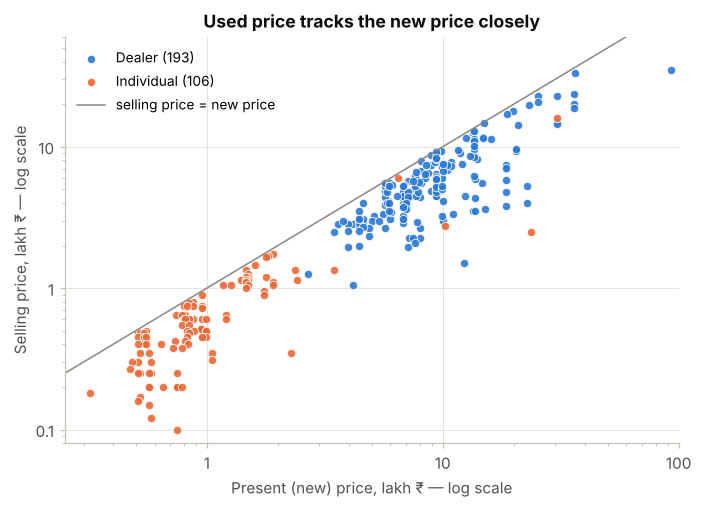

Pearson r(Present_Price, Selling_Price) = 0.876


In [11]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))
for seller, color in [("Dealer", BLUE), ("Individual", ORANGE)]:
    d = df[df["Seller_Type"] == seller]
    ax.scatter(d["Present_Price"], d["Selling_Price"], s=30, color=color,
               edgecolor="white", linewidth=0.6, alpha=0.9, label=f"{seller} ({len(d)})")
lims = [0.25, 100]
ax.plot(lims, lims, color=MUTED, linewidth=1, label="selling price = new price")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(plain_numbers); ax.yaxis.set_major_formatter(plain_numbers)
ax.set_xlim(0.25, 100); ax.set_ylim(0.08, 60)
ax.set_xlabel("Present (new) price, lakh ₹ — log scale")
ax.set_ylabel("Selling price, lakh ₹ — log scale")
ax.set_title("Used price tracks the new price closely")
ax.legend(loc="upper left")
save(fig, "fig02_present_vs_selling")
print("Pearson r(Present_Price, Selling_Price) =",
      round(df["Present_Price"].corr(df["Selling_Price"]), 3))

**Interpretation.** Almost every point lies **below the diagonal**: a used vehicle sells for less than its new price (depreciation). The points form a tight band, so `Present_Price` should be the strongest predictor (r = 0.88). The orange cluster at the bottom left is the individual sellers, nearly all of them two-wheelers.

### 2.3 Correlation heatmap of the numerical features

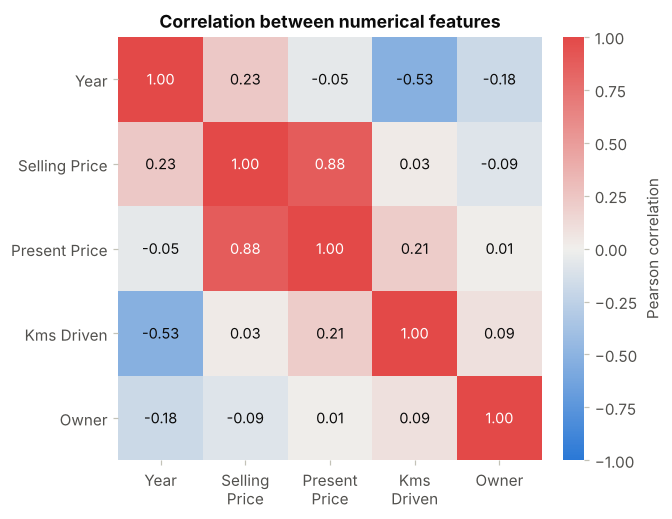

Present_Price    0.876
Year             0.234
Kms_Driven       0.029
Owner           -0.088
Name: Selling_Price, dtype: float64

In [12]:
num_cols = ["Year", "Selling_Price", "Present_Price", "Kms_Driven", "Owner"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(6.2, 5.0))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), [c.replace("_", "\n") for c in num_cols])
ax.set_yticks(range(len(num_cols)), [c.replace("_", " ") for c in num_cols])
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        r = corr.iloc[i, j]
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=9.5,
                color="white" if abs(r) > 0.6 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cb.outline.set_visible(False); cb.set_label("Pearson correlation", color=INK2)
ax.set_title("Correlation between numerical features")
save(fig, "fig03_correlation_heatmap")
corr["Selling_Price"].drop("Selling_Price").sort_values(ascending=False).round(3)

**Interpretation.**
* `Selling_Price` is strongly correlated with only one feature: **`Present_Price` (r = 0.88)**.
* `Year` is weakly positive (0.23): newer vehicles sell for more.
* `Kms_Driven` (0.03) and `Owner` (−0.09) show almost no linear relationship with price on their own.
* `Year` and `Kms_Driven` are moderately negatively correlated (−0.53): older vehicles have been driven more.

Correlation measures only one-variable *linear* relationships. Age turns out to matter much more once we compare vehicles with the same original price (section 3.1).

### 2.4 Selling price across the categorical features

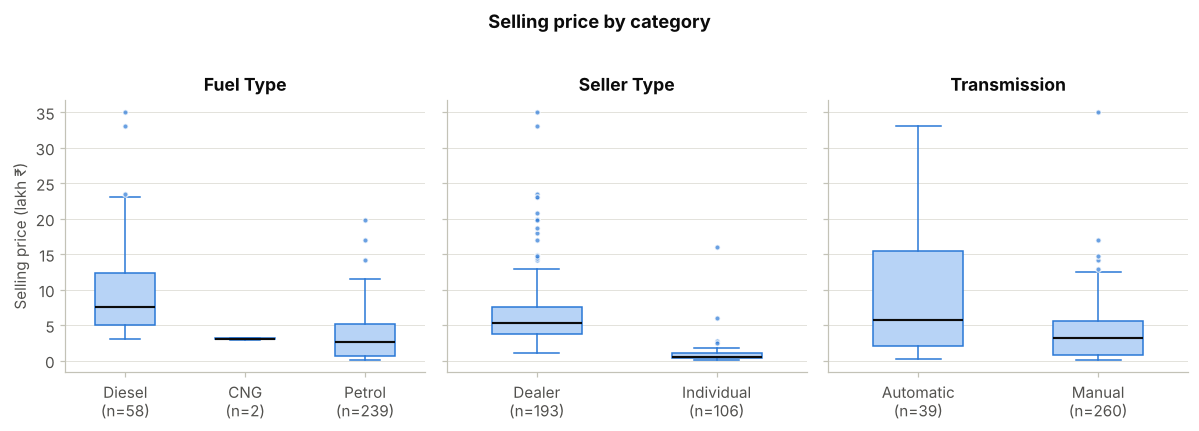

,count,mean,std,min,25%,50%,75%,max
Transmission,,,,,,,,
Automatic,39.0,9.07,8.59,0.17,2.0,5.75,15.45,33.0
Manual,260.0,3.92,3.78,0.10,0.8,3.25,5.54,35.0


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, col in zip(axes, ["Fuel_Type", "Seller_Type", "Transmission"]):
    groups = df.groupby(col)["Selling_Price"]
    order = groups.median().sort_values(ascending=False).index
    data = [df.loc[df[col] == g, "Selling_Price"] for g in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.5,
                    medianprops=dict(color=INK, linewidth=1.4),
                    boxprops=dict(facecolor=LIGHT_BLUE, edgecolor=BLUE, linewidth=1),
                    whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
                    flierprops=dict(marker="o", markersize=3.5, markerfacecolor=BLUE,
                                    markeredgecolor="white", alpha=0.7))
    ax.set_xticks(range(1, len(order) + 1), [f"{g}\n(n={len(d)})" for g, d in zip(order, data)])
    ax.set_title(col.replace("_", " "))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Selling price (lakh ₹)")
fig.suptitle("Selling price by category", fontweight="bold", color=INK, y=1.02)
fig.tight_layout()
save(fig, "fig04_price_by_category")
df.groupby("Transmission")["Selling_Price"].describe().round(2)

In [14]:
for col in ["Fuel_Type", "Seller_Type", "Transmission"]:
    print(df.groupby(col)["Selling_Price"].agg(["count", "mean", "median"]).round(2), "\n")

           count   mean  median
Fuel_Type                      
CNG            2   3.10    3.10
Diesel        58  10.10    7.60
Petrol       239   3.26    2.65 

             count  mean  median
Seller_Type                     
Dealer         193  6.63    5.25
Individual     106  0.87    0.52 

              count  mean  median
Transmission                     
Automatic        39  9.07    5.75
Manual          260  3.92    3.25 



**Interpretation.**
* **Diesel** vehicles sell for much more (median 7.60 vs 2.65 lakh for petrol), because diesel is common on larger cars and SUVs.
* **Dealer** listings (median 5.25) are far above **individual** listings (0.52), mostly because individuals are selling two-wheelers.
* **Automatics** have a higher median price (5.75 vs 3.25) and a much wider spread.
* **CNG** has only 2 vehicles, so anything the model learns about CNG is unreliable.

## 3. Data preprocessing

### 3.1 Feature engineering — vehicle age
A car's *model year* is just a label; what drives the price is **how old the car is** at the time of sale
(older ⇒ more wear, outdated features, warranty expired). The newest listing is model year 2018, so we
measure age relative to **2019** (the year after the newest model year, i.e. roughly when the listings were collected).

> The choice of reference year only shifts the intercept by a constant — it does not change any slope
> coefficient or any prediction.

In [15]:
REFERENCE_YEAR = df["Year"].max() + 1          # 2019
df["Car_Age"] = REFERENCE_YEAR - df["Year"]
df["Car_Age"].describe().round(2)

count    299.00
mean       5.38
std        2.90
min        1.00
25%        3.00
50%        5.00
75%        7.00
max       16.00
Name: Car_Age, dtype: float64

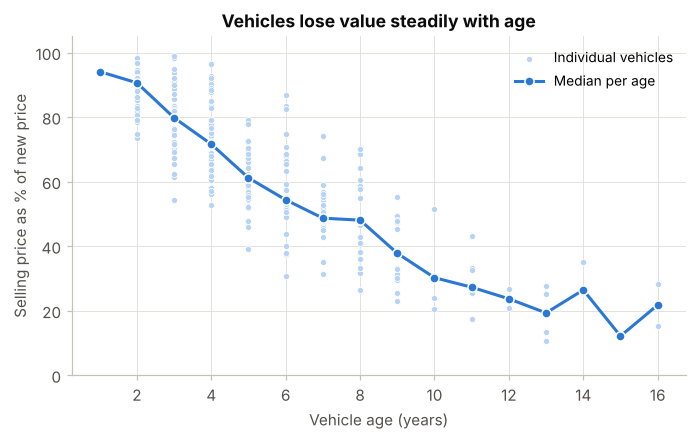

Correlation(Car_Age, Selling_Price) = -0.234


Car_Age,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
median,94.1,90.6,79.8,71.6,61.2,54.4,48.7,48.1,37.8,30.2,27.3,23.7,19.3,26.4,12.1,21.8
count,1.0,35.0,49.0,60.0,38.0,33.0,23.0,19.0,15.0,6.0,7.0,2.0,4.0,4.0,1.0,2.0


In [16]:
# Why age matters: share of the original price that a vehicle still sells for, by age
df["Retained_Value_%"] = 100 * df["Selling_Price"] / df["Present_Price"]
by_age = df.groupby("Car_Age")["Retained_Value_%"].agg(["median", "count"])

fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.scatter(df["Car_Age"], df["Retained_Value_%"], s=16, color=LIGHT_BLUE,
           edgecolor="white", linewidth=0.5, label="Individual vehicles")
ax.plot(by_age.index, by_age["median"], color=BLUE, linewidth=2, marker="o",
        markersize=6, markeredgecolor="white", label="Median per age")
ax.set_xlabel("Vehicle age (years)"); ax.set_ylabel("Selling price as % of new price")
ax.set_ylim(0, 105)
ax.set_title("Vehicles lose value steadily with age")
ax.legend(loc="upper right")
save(fig, "fig05_value_retained_by_age")
print("Correlation(Car_Age, Selling_Price) =", round(df["Car_Age"].corr(df["Selling_Price"]), 3))
by_age.round(1).T

**Interpretation.** The retained-value curve shows why age matters. The median vehicle sells for about **90 % of its new price at 2 years old, ~61 % at 5 years and ~30 % at 10 years**. On its own, age correlates only −0.23 with selling price, because cheap and expensive vehicles of every age are mixed together. Combined with `Present_Price`, age tells the model **how much of the original value is left**.

### 3.2 Selecting features — categorical vs numerical
* **Dropped `Car_Name`** – 98 different names in 299 rows. One-hot encoding it would add ~97 sparse
  columns (most names appear once or twice), which invites over-fitting and fails on names never seen in
  training. Much of the information it carries (luxury vs budget model) is already in `Present_Price`.
* **Dropped `Year`** – replaced by `Car_Age` (keeping both would give two perfectly correlated columns).
* **Dropped `Retained_Value_%`** – it was only used for the plot above, and it is computed *from the target*
  (using it would leak the answer into the inputs).

In [17]:
TARGET_P1 = "Selling_Price"
NUMERIC_P1 = ["Present_Price", "Kms_Driven", "Owner", "Car_Age"]
CATEGORICAL_P1 = ["Fuel_Type", "Seller_Type", "Transmission"]

print(f"Numerical features   ({len(NUMERIC_P1)}): {NUMERIC_P1}")
print(f"Categorical features ({len(CATEGORICAL_P1)}):")
for c in CATEGORICAL_P1:
    print(f"   {c:<13} -> categories {sorted(df[c].unique())}")

Numerical features   (4): ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']
Categorical features (3):
   Fuel_Type     -> categories ['CNG', 'Diesel', 'Petrol']
   Seller_Type   -> categories ['Dealer', 'Individual']
   Transmission  -> categories ['Automatic', 'Manual']


### 3.3 Converting categorical variables to numbers (one-hot encoding)
Each categorical column becomes 0/1 *dummy* columns. We use `drop_first=True` so one category per feature
is the **baseline** (CNG for fuel, Dealer for seller, Automatic for transmission). This avoids the
"dummy-variable trap" (perfect multicollinearity) and makes each dummy coefficient read as
*"difference compared with the baseline"*.

In [18]:
X_p1 = pd.get_dummies(df[NUMERIC_P1 + CATEGORICAL_P1], columns=CATEGORICAL_P1,
                      drop_first=True, dtype=int)
y_p1 = df[TARGET_P1]
print("Final feature matrix:", X_p1.shape)
X_p1.head()

Final feature matrix: (299, 8)


,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,5.59,27000,0,5,0,1,0,1
1,9.54,43000,0,6,1,0,0,1
2,9.85,6900,0,2,0,1,0,1
3,4.15,5200,0,8,0,1,0,1
4,6.87,42450,0,5,1,0,0,1


### 3.4 Train / test split (80 % / 20 %, `random_state = 1`)

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X_p1, y_p1, test_size=0.20, random_state=RANDOM_STATE)
print(f"Training set: {X_train.shape[0]} rows | Test set: {X_test.shape[0]} rows")
print(f"Mean selling price – train: {y_train.mean():.2f}, test: {y_test.mean():.2f}")

Training set: 239 rows | Test set: 60 rows
Mean selling price – train: 4.57, test: 4.69


### 3.5 Scaling (standardisation)
The numerical features live on very different scales (`Kms_Driven` is in the tens of thousands,
`Owner` is 0–3). We standardise them to mean 0 and standard deviation 1:

$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

* For ordinary linear regression this **does not change the predictions**, but it makes the coefficients
  **comparable** (each one = effect of a one-standard-deviation change), so we can rank feature importance.
* The scaler is **fit on the training set only** and then applied to the test set, so no information from
  the test set leaks into training.
* The 0/1 dummy columns are left as they are.

In [20]:
scaler_p1 = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[NUMERIC_P1] = scaler_p1.fit_transform(X_train[NUMERIC_P1])
X_test_s[NUMERIC_P1] = scaler_p1.transform(X_test[NUMERIC_P1])
X_train_s[NUMERIC_P1].describe().loc[["mean", "std"]].round(3)

,Present_Price,Kms_Driven,Owner,Car_Age
mean,-0.000,-0.000,0.000,0.000
std,1.002,1.002,1.002,1.002


## 4. Model building — Linear Regression

In [21]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_s, y_train)

coef = pd.DataFrame({"feature": X_train_s.columns, "coef_standardised": lin_reg.coef_})
# Convert numeric coefficients back to "per original unit" for a business reading
scale = dict(zip(NUMERIC_P1, scaler_p1.scale_))
unit_size = {"Kms_Driven": 10_000}   # report kilometres per 10,000 km (per 1 km is ~0)
coef["coef_per_original_unit"] = [c / scale[f] * unit_size.get(f, 1) if f in scale else c
                                  for f, c in zip(coef["feature"], coef["coef_standardised"])]
coef["unit"] = coef["feature"].map({"Present_Price": "per +1 lakh new price",
                                    "Kms_Driven": "per +10,000 km", "Owner": "per extra owner",
                                    "Car_Age": "per +1 year of age"}).fillna("vs. baseline category")
coef = coef.reindex(coef["coef_standardised"].abs().sort_values(ascending=False).index)
print(f"Intercept: {lin_reg.intercept_:.3f}")
coef.round(4)

Intercept: 4.385


,feature,coef_standardised,coef_per_original_unit,unit
0,Present_Price,3.5623,0.5292,per +1 lakh new price
4,Fuel_Type_Diesel,2.1211,2.1211,vs. baseline category
3,Car_Age,-1.2349,-0.4180,per +1 year of age
7,Transmission_Manual,-0.5274,-0.5274,vs. baseline category
5,Fuel_Type_Petrol,0.4981,0.4981,vs. baseline category
6,Seller_Type_Individual,-0.4731,-0.4731,vs. baseline category
1,Kms_Driven,-0.2522,-0.0599,"per +10,000 km"
2,Owner,-0.2481,-0.9443,per extra owner


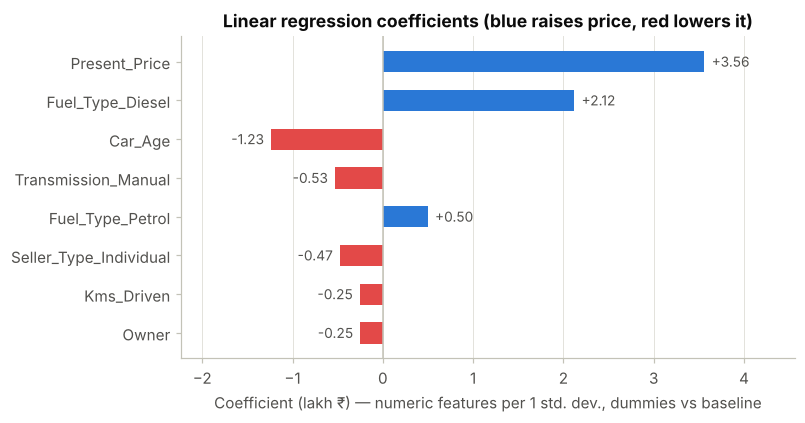

In [22]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
c = coef.iloc[::-1]
colors = [BLUE if v > 0 else RED for v in c["coef_standardised"]]
ax.barh(c["feature"], c["coef_standardised"], color=colors, height=0.55)
for y, v in enumerate(c["coef_standardised"]):
    ax.text(v + (0.08 if v >= 0 else -0.08), y, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=INK2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.grid(axis="y", visible=False)
lo, hi = c["coef_standardised"].min(), c["coef_standardised"].max()
ax.set_xlim(lo - 1.0, hi + 1.0)
ax.set_xlabel("Coefficient (lakh ₹) — numeric features per 1 std. dev., dummies vs baseline")
ax.set_title("Linear regression coefficients (blue raises price, red lowers it)")
save(fig, "fig06_linreg_coefficients")

**Interpretation.** The intercept (4.39) is the predicted price of a vehicle with average numeric features that belongs to every baseline category (CNG, Dealer, Automatic).
* **`Present_Price` is by far the most important feature:** +3.56 lakh per standard deviation (≈ 6.7 lakh) of new price. Holding the other features fixed, each extra lakh of new price adds about **0.53 lakh** to the used price.
* **Diesel** vehicles sell for about 2.1 lakh more than the CNG baseline, and about **1.6 lakh more than petrol** (2.12 − 0.50). The CNG comparison rests on only 2 vehicles, so the diesel-vs-petrol gap is the reliable reading.
* **`Car_Age`** is the main negative factor: about **−0.42 lakh per extra year**.
* The remaining effects are small: **manual** −0.53 lakh vs automatic, **individual seller** −0.47 lakh vs dealer, **per 10,000 km** −0.06 lakh, and **per extra previous owner** −0.94 lakh. Only 11 vehicles had a previous owner, so the owner effect is uncertain.

## 5. Model evaluation

In [23]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

y_pred_train = lin_reg.predict(X_train_s)
y_pred_test = lin_reg.predict(X_test_s)
metrics_p1 = pd.DataFrame({"Train": regression_metrics(y_train, y_pred_train),
                           "Test": regression_metrics(y_test, y_pred_test)}).T
metrics_p1.round(4)

,MAE,MSE,RMSE,R2
Train,1.1670,2.9400,1.7146,0.8599
Test,1.2568,5.1328,2.2656,0.8709


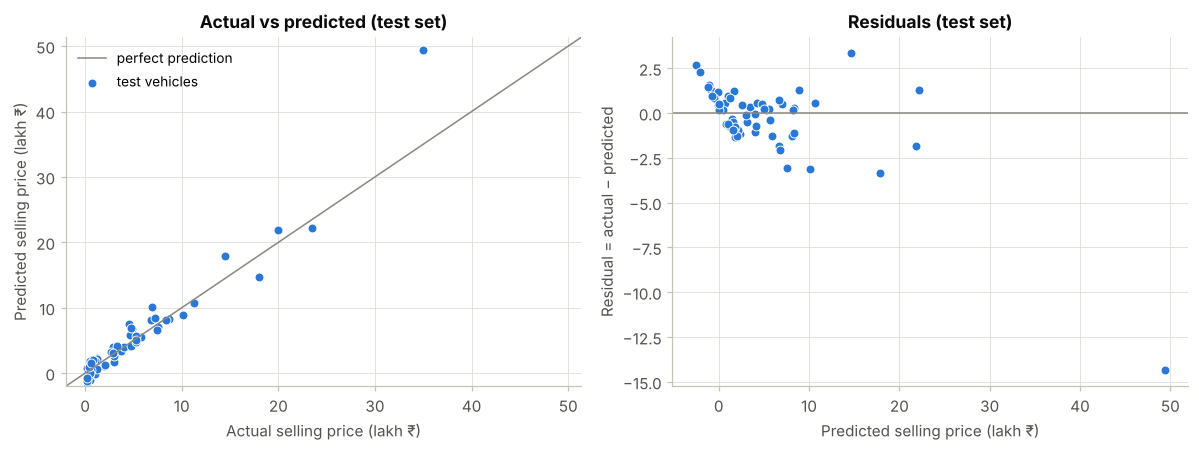

Negative predictions on test set: 9
Largest absolute test errors:


,Car_Name,actual,predicted,error
85,land cruiser,35.00,49.36,-14.36
78,fortuner,14.50,17.86,-3.36
51,innova,18.00,14.65,3.35
59,corolla altis,6.95,10.07,-3.12
70,corolla altis,4.50,7.58,-3.08


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
lim = [-2, max(y_test.max(), y_pred_test.max()) + 2]
ax.plot(lim, lim, color=MUTED, linewidth=1, label="perfect prediction")
ax.scatter(y_test, y_pred_test, s=34, color=BLUE, edgecolor="white", linewidth=0.6,
           label="test vehicles")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual selling price (lakh ₹)"); ax.set_ylabel("Predicted selling price (lakh ₹)")
ax.set_title("Actual vs predicted (test set)"); ax.legend(loc="upper left")

ax = axes[1]
resid = y_test - y_pred_test
ax.axhline(0, color=MUTED, linewidth=1)
ax.scatter(y_pred_test, resid, s=34, color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_xlabel("Predicted selling price (lakh ₹)"); ax.set_ylabel("Residual = actual − predicted")
ax.set_title("Residuals (test set)")
fig.tight_layout()
save(fig, "fig07_actual_vs_predicted")
print(f"Negative predictions on test set: {(y_pred_test < 0).sum()}")
print(f"Largest absolute test errors:")
err = pd.DataFrame({"Car_Name": df.loc[y_test.index, "Car_Name"], "actual": y_test,
                    "predicted": y_pred_test.round(2), "error": (y_test - y_pred_test).round(2)})
err.reindex(err["error"].abs().sort_values(ascending=False).index).head(5)

In [25]:
# The biggest error is an extrapolation: is the Land Cruiser's new price inside the training range?
print(f"Max Present_Price in training set: {X_train['Present_Price'].max():.2f} lakh")
print(f"Land Cruiser Present_Price (test): {df.loc[df['Car_Name'] == 'land cruiser', 'Present_Price'].iloc[0]:.2f} lakh")
sq_err = (y_test - y_pred_test) ** 2
lc = df.loc[y_test.index, "Car_Name"].eq("land cruiser").values
print(f"Share of test squared error from that one car: {sq_err[lc].sum() / sq_err.sum():.1%}")
print("Test metrics without it:",
      {k: round(float(v), 3) for k, v in regression_metrics(y_test[~lc], y_pred_test[~lc]).items()})
print(f"CNG rows in training set: {(X_train[['Fuel_Type_Diesel', 'Fuel_Type_Petrol']].sum(axis=1) == 0).sum()}")

Max Present_Price in training set: 36.23 lakh
Land Cruiser Present_Price (test): 92.60 lakh
Share of test squared error from that one car: 67.0%
Test metrics without it: {'MAE': 1.035, 'MSE': 1.723, 'RMSE': 1.313, 'R2': 0.93}
CNG rows in training set: 2


**Interpretation of the test-set metrics**
* **MAE = 1.26 lakh.** On average a prediction is off by about ₹126,000, in either direction.
* **MSE = 5.13 lakh².** The average squared error. Its unit (lakh²) is hard to read directly, but it is the quantity least squares minimises, and it punishes big mistakes heavily.
* **RMSE = 2.27 lakh.** The square root of MSE, back in lakh: a "typical" error that weights large mistakes more. RMSE being much larger than MAE means a few predictions are badly wrong.
* **R² = 0.871.** The model explains about **87 % of the variation** in selling prices of vehicles it has never seen.

Train and test R² are close (0.86 vs 0.87), so there is **no sign of over-fitting**.

The residual plot shows two weaknesses:
1. **One huge error.** The Land Cruiser has a new price of 92.6 lakh, far beyond anything in the training set (maximum 36.2). The model predicts 49.4 for it vs the actual 35.0. This single extrapolation causes about **67 % of the test squared error**; without it, test RMSE would be 1.31 and R² 0.93.
2. **Negative predictions.** 9 cheap two-wheelers get predicted prices below zero. Depreciation works in percentages, and a straight line cannot capture that at the bottom of the price range.

## 6. Model improvement — K-Fold Cross-Validation

A single 80/20 split can be lucky or unlucky. K-fold CV splits the **training data** into *K* folds, trains on
*K − 1* of them and validates on the remaining one, repeating *K* times so every row is validated exactly once.
The mean score estimates generalisation error; the standard deviation shows how **stable** the model is.

The scaler is placed inside a `Pipeline`, so in every fold it is re-fit on that fold's training part only
(no leakage). We try **three fold scenarios: K = 3, 5 and 10**.

In [26]:
preprocess_p1 = ColumnTransformer([("num", StandardScaler(), NUMERIC_P1)], remainder="passthrough")
pipe_p1 = Pipeline([("prep", preprocess_p1), ("model", LinearRegression())])

cv_rows, cv_fold_rmse = [], {}
for k in [3, 5, 10]:
    kf = KFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    res = cross_validate(pipe_p1, X_train, y_train, cv=kf,
                         scoring=("neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"))
    rmse, mae, r2 = -res["test_neg_root_mean_squared_error"], -res["test_neg_mean_absolute_error"], res["test_r2"]
    cv_fold_rmse[k] = rmse
    cv_rows.append({"K": k, "RMSE mean": rmse.mean(), "RMSE std": rmse.std(),
                    "MAE mean": mae.mean(), "MAE std": mae.std(),
                    "R2 mean": r2.mean(), "R2 std": r2.std(),
                    "RMSE min": rmse.min(), "RMSE max": rmse.max()})
cv_p1 = pd.DataFrame(cv_rows).set_index("K")
cv_p1.round(3)

,RMSE mean,RMSE std,MAE mean,MAE std,R2 mean,R2 std,RMSE min,RMSE max
K,,,,,,,,
3,2.048,0.296,1.294,0.125,0.771,0.051,1.631,2.286
5,1.966,0.281,1.242,0.140,0.771,0.121,1.706,2.499
10,1.943,0.650,1.274,0.305,0.773,0.137,1.107,3.422


In [27]:
for k, scores in cv_fold_rmse.items():
    print(f"K={k:>2}  RMSE per fold: {np.round(scores, 3)}")

K= 3  RMSE per fold: [2.228 2.286 1.631]
K= 5  RMSE per fold: [1.706 2.499 1.986 1.816 1.823]
K=10  RMSE per fold: [1.785 1.689 3.422 1.107 2.296 2.088 2.378 1.182 1.386 2.099]


In [28]:
# Compare: single train/test split vs cross-validated average
comparison = pd.DataFrame({
    "Single split (test set)": [metrics_p1.loc["Test", "RMSE"], metrics_p1.loc["Test", "MAE"], metrics_p1.loc["Test", "R2"]],
    **{f"{k}-fold CV mean": [cv_p1.loc[k, "RMSE mean"], cv_p1.loc[k, "MAE mean"], cv_p1.loc[k, "R2 mean"]]
       for k in cv_p1.index}}, index=["RMSE", "MAE", "R2"])
comparison.round(3)

,Single split (test set),3-fold CV mean,5-fold CV mean,10-fold CV mean
RMSE,2.266,2.048,1.966,1.943
MAE,1.257,1.294,1.242,1.274
R2,0.871,0.771,0.771,0.773


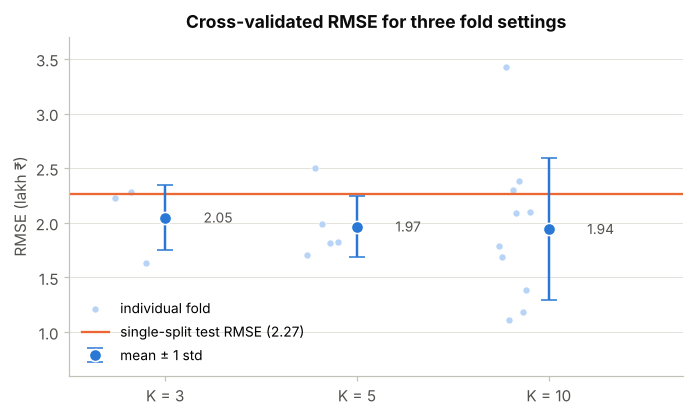

In [29]:
fig, ax = plt.subplots(figsize=(7.2, 4.0))
ks = list(cv_fold_rmse)
for i, k in enumerate(ks):
    s = cv_fold_rmse[k]
    jitter = np.linspace(-0.26, -0.10, len(s))   # folds drawn just left of the mean marker
    ax.scatter(np.full(len(s), i) + jitter, s, s=22, color=LIGHT_BLUE, edgecolor="white",
               linewidth=0.5, label="individual fold" if i == 0 else None, zorder=2)
    ax.errorbar(i, s.mean(), yerr=s.std(), fmt="o", color=BLUE, markersize=8,
                markeredgecolor="white", capsize=5, linewidth=1.6,
                label="mean ± 1 std" if i == 0 else None, zorder=3)
    ax.text(i + 0.2, s.mean(), f"{s.mean():.2f}", va="center", fontsize=9, color=INK2)
test_rmse = metrics_p1.loc["Test", "RMSE"]
ax.axhline(test_rmse, color=ORANGE, linewidth=1.5, label=f"single-split test RMSE ({test_rmse:.2f})")
ax.set_xticks(range(len(ks)), [f"K = {k}" for k in ks])
ax.set_xlim(-0.5, len(ks) - 0.3)
ax.set_ylabel("RMSE (lakh ₹)")
ax.set_title("Cross-validated RMSE for three fold settings")
ax.grid(axis="x", visible=False)
ax.set_ylim(0.6, 3.7)
ax.legend(loc="lower left")
save(fig, "fig08_kfold_rmse")

**Interpretation.**
* All three settings give a similar mean RMSE: **2.05 (K = 3), 1.97 (K = 5) and 1.94 (K = 10)**. Mean MAE is 1.24–1.29 lakh, very close to the test MAE (1.26).
* The single-split test RMSE (2.27) is **higher than the cross-validated average (~1.97)**. The single split was somewhat "unlucky": the out-of-range Land Cruiser landed in its test set. Going the other way, the CV R² (~0.77) is lower than the test R² (0.87) and varies more, because R² also depends on how spread out the prices in each small fold are.
* The fold-to-fold standard deviation is about **0.28–0.30 lakh for K = 3 and 5** (~15 % of the mean). With K = 10 each fold holds only ~24 vehicles, and one fold reaches RMSE 3.42 because it contains several expensive SUVs, so the spread grows to 0.65.
* **Verdict:** the model is **reasonably stable for typical vehicles**. Its error changes mainly with whether the rare expensive SUVs fall in the validation data. Cross-validation does not change the model itself, but it gives a more trustworthy error estimate than one split. K = 5 is a good compromise.

## 7. Conclusion for Part 1

**Can we predict selling price?** Yes, reasonably well. The linear model explains about 77–87 % of the variance in selling price, with a typical absolute error of about **1.25 lakh**. Its most important drivers also make business sense: a higher new price raises the selling price, diesel raises it, and age lowers it.

**Main limitations**
1. Prices are skewed and depreciation is proportional, so a straight line predicts **negative prices for cheap two-wheelers** and over-predicts very expensive cars. Modelling `log(Selling_Price)` would address both.
2. The model **extrapolates badly** outside the range it was trained on (the Land Cruiser).
3. The data is small: 299 rows, only 2 CNG vehicles and only 11 vehicles with previous owners, so some coefficients are unreliable.
4. Cars and two-wheelers are mixed together in a single linear model.

**Three extra features that could improve the model**
1. **Brand / body type / vehicle category** (car vs motorcycle vs scooter; hatchback, sedan or SUV).
2. **Engine size, power and trim level** (base vs top variant).
3. **Condition and history:** accident record, service history, insurance validity.

---
# Part 2 — Predicting Automatic vs Manual Transmission with Logistic Regression

**Problem statement.** Using a listing's price, age, mileage, fuel type, seller type and ownership history,
predict whether the vehicle has an **automatic** or a **manual** gearbox. Target **y = `Is_Automatic`**
(1 = Automatic, 0 = Manual).

## 8. Data preparation

In [30]:
df["Is_Automatic"] = (df["Transmission"] == "Automatic").astype(int)
counts = df["Transmission"].value_counts()
print(counts.to_string())
print(f"\nShare automatic: {df['Is_Automatic'].mean():.1%}  ->  the classes are imbalanced.")
print(f"A 'model' that always says Manual would already be {1 - df['Is_Automatic'].mean():.1%} accurate.")

Transmission
Manual       260
Automatic     39

Share automatic: 13.0%  ->  the classes are imbalanced.
A 'model' that always says Manual would already be 87.0% accurate.


In [31]:
# How do automatic and manual vehicles differ? (medians)
profile = df.groupby("Transmission")[["Selling_Price", "Present_Price", "Car_Age",
                                       "Kms_Driven", "Owner"]].median()
profile["n"] = counts
profile.round(2)

,Selling_Price,Present_Price,Car_Age,Kms_Driven,Owner,n
Transmission,,,,,,
Automatic,5.75,12.04,4.0,31427.0,0.0,39
Manual,3.25,5.80,5.0,32000.0,0.0,260


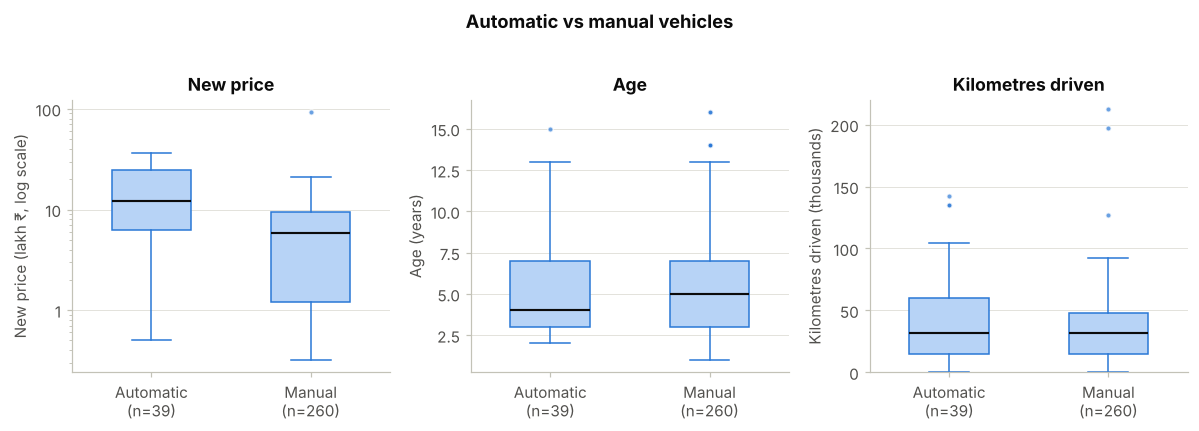

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
specs = [("Present_Price", "New price (lakh ₹, log scale)", True),
         ("Car_Age", "Age (years)", False),
         ("Kms_Driven", "Kilometres driven (thousands)", False)]
order = ["Automatic", "Manual"]
for ax, (col, label, log) in zip(axes, specs):
    data = [df.loc[df["Transmission"] == t, col] / (1000 if col == "Kms_Driven" else 1) for t in order]
    ax.boxplot(data, patch_artist=True, widths=0.5,
               medianprops=dict(color=INK, linewidth=1.4),
               boxprops=dict(facecolor=LIGHT_BLUE, edgecolor=BLUE, linewidth=1),
               whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
               flierprops=dict(marker="o", markersize=3.5, markerfacecolor=BLUE,
                               markeredgecolor="white", alpha=0.7))
    ax.set_xticks([1, 2], [f"{t}\n(n={len(d)})" for t, d in zip(order, data)])
    if log:
        ax.set_yscale("log"); ax.yaxis.set_major_formatter(plain_numbers)
    if col == "Kms_Driven":
        ax.set_ylim(0, 220)   # one scooter with 500,000 km is cut off for readability
    ax.set_ylabel(label); ax.grid(axis="x", visible=False)
    ax.set_title(label.split(" (")[0])
fig.suptitle("Automatic vs manual vehicles", fontweight="bold", color=INK, y=1.02)
fig.tight_layout()
save(fig, "fig09_automatic_vs_manual")

In [33]:
# Share of automatics within each category
for col in ["Fuel_Type", "Seller_Type"]:
    print(df.groupby(col)["Is_Automatic"].agg(n="count", automatic="sum", share="mean").round(3), "\n")

             n  automatic  share
Fuel_Type                       
CNG          2          0  0.000
Diesel      58         11  0.190
Petrol     239         28  0.117 

               n  automatic  share
Seller_Type                       
Dealer       193         28  0.145
Individual   106         11  0.104 



In [34]:
# Share of automatics by selling-price band
bands = pd.cut(df["Selling_Price"], [0, 2, 5, 10, 40], labels=["< 2", "2–5", "5–10", "> 10"])
df.groupby(bands, observed=True)["Is_Automatic"].agg(n="count", automatic="sum", share="mean").round(3)

,n,automatic,share
Selling_Price,,,
< 2,108,10,0.093
2–5,86,5,0.058
5–10,78,10,0.128
> 10,27,14,0.519


**Interpretation.**
* Only **39 of 299 vehicles (13 %) are automatic**, so the classes are **imbalanced**. Always guessing "Manual" is already 87 % accurate, and any useful model has to beat that.
* Automatics are clearly **more expensive**: median new price 12.0 vs 5.8 lakh, median selling price 5.75 vs 3.25. About **52 % of vehicles selling for more than 10 lakh are automatic**, compared with only 6–13 % in each of the cheaper price bands.
* They are only **slightly newer** (median age 4 vs 5 years), and their **mileage is about the same** (≈ 31–32 thousand km).
* 9 of the 11 automatics sold by individuals are **scooters** (Honda Activa, TVS Jupyter, Suzuki Access, …).

**Feature selection.** `Car_Name` and `Year` are dropped for the same reasons as in Part 1, and
`Transmission` itself is now the target. In this part the selling price is a legitimate *input*.

* Numerical (5): `Selling_Price`, `Present_Price`, `Kms_Driven`, `Owner`, `Car_Age`
* Categorical (2): `Fuel_Type` (CNG / Diesel / Petrol), `Seller_Type` (Dealer / Individual) → one-hot, `drop_first=True`

The split is again **80 % / 20 % with `random_state = 1`**, and it is **stratified** on the target so that the
small automatic class (≈13 %) is represented in the same proportion in both sets. Numerical features are
standardised (fit on training data only) — for logistic regression this also helps the solver converge and
makes the coefficients comparable.

In [35]:
TARGET_P2 = "Is_Automatic"
NUMERIC_P2 = ["Selling_Price", "Present_Price", "Kms_Driven", "Owner", "Car_Age"]
CATEGORICAL_P2 = ["Fuel_Type", "Seller_Type"]

X_p2 = pd.get_dummies(df[NUMERIC_P2 + CATEGORICAL_P2], columns=CATEGORICAL_P2,
                      drop_first=True, dtype=int)
y_p2 = df[TARGET_P2]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_p2, y_p2, test_size=0.20, random_state=RANDOM_STATE, stratify=y_p2)

scaler_p2 = StandardScaler()
X2_train_s, X2_test_s = X2_train.copy(), X2_test.copy()
X2_train_s[NUMERIC_P2] = scaler_p2.fit_transform(X2_train[NUMERIC_P2])
X2_test_s[NUMERIC_P2] = scaler_p2.transform(X2_test[NUMERIC_P2])

print("Features:", list(X_p2.columns))
print(f"Train: {len(y2_train)} rows ({y2_train.sum()} automatic) | "
      f"Test: {len(y2_test)} rows ({y2_test.sum()} automatic)")

Features: ['Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner', 'Car_Age', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual']
Train: 239 rows (31 automatic) | Test: 60 rows (8 automatic)


## 9. Model training — Logistic Regression

In [36]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X2_train_s, y2_train)

coef2 = pd.DataFrame({"feature": X2_train_s.columns, "coef": log_reg.coef_[0]})
coef2["odds_ratio"] = np.exp(coef2["coef"])
coef2 = coef2.reindex(coef2["coef"].abs().sort_values(ascending=False).index)
print(f"Intercept: {log_reg.intercept_[0]:.3f}")
coef2.round(3)

Intercept: -2.610


,feature,coef,odds_ratio
0,Selling_Price,0.971,2.641
7,Seller_Type_Individual,0.603,1.828
6,Fuel_Type_Petrol,0.429,1.535
5,Fuel_Type_Diesel,-0.320,0.726
2,Kms_Driven,0.179,1.196
4,Car_Age,0.158,1.171
1,Present_Price,0.129,1.137
3,Owner,0.112,1.119


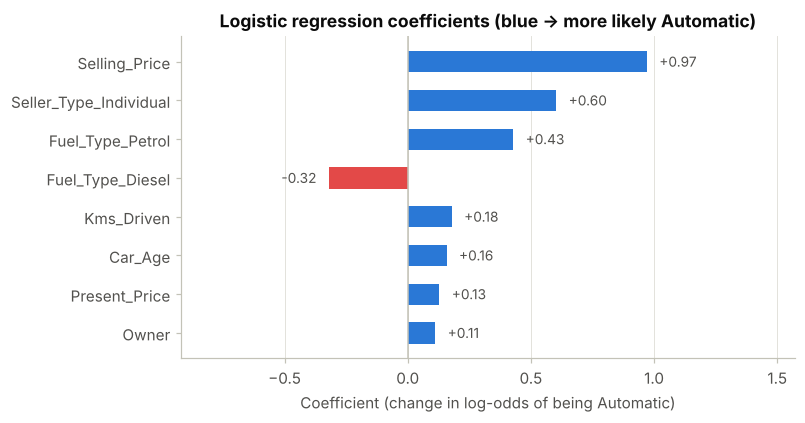

In [37]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
c = coef2.iloc[::-1]
colors = [BLUE if v > 0 else RED for v in c["coef"]]
ax.barh(c["feature"], c["coef"], color=colors, height=0.55)
for y, v in enumerate(c["coef"]):
    ax.text(v + (0.05 if v >= 0 else -0.05), y, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=INK2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_xlim(c["coef"].min() - 0.6, c["coef"].max() + 0.6)
ax.set_xlabel("Coefficient (change in log-odds of being Automatic)")
ax.set_title("Logistic regression coefficients (blue → more likely Automatic)")
save(fig, "fig10_logreg_coefficients")

**Interpretation** (features are standardised, so the coefficients are comparable; the odds ratio is e^coef).
* **`Selling_Price` is the strongest predictor (+0.97).** A vehicle priced one standard deviation higher (≈ 5 lakh) has about **2.6 times the odds** of being automatic.
* **`Seller_Type_Individual` (+0.60, odds × 1.8)** looks surprising at first. It comes from the automatic **scooters**, all sold by individuals: among cheap vehicles, the automatics are scooters.
* **Fuel type:** petrol is +0.43 and diesel −0.32 relative to CNG. CNG has only 2 vehicles, so neither number is trustworthy on its own. The useful reading is that, at the same price, **petrol vehicles are more likely to be automatic than diesel ones**.
* `Kms_Driven` (+0.18), `Car_Age` (+0.16), `Present_Price` (+0.13) and `Owner` (+0.11) have **small effects**.
    * `Present_Price` looks weak only because it is highly correlated with `Selling_Price` (r = 0.88). The two share the same "expensive vehicle" signal, and the model hands most of it to `Selling_Price` (multicollinearity).
    * The small positive age effect is *conditional*: at the same selling price, an older vehicle must have cost more when new.

## 10. Model evaluation

In [38]:
y2_pred = log_reg.predict(X2_test_s)
y2_proba = log_reg.predict_proba(X2_test_s)[:, 1]

cm = confusion_matrix(y2_test, y2_pred, labels=[0, 1])
acc = accuracy_score(y2_test, y2_pred)
prec = precision_score(y2_test, y2_pred, pos_label=1, zero_division=0)
rec = recall_score(y2_test, y2_pred, pos_label=1, zero_division=0)
baseline_acc = 1 - y2_test.mean()

print(pd.DataFrame(cm, index=["Actual Manual", "Actual Automatic"],
                   columns=["Predicted Manual", "Predicted Automatic"]), "\n")
print(f"Accuracy                      : {acc:.3f}   (baseline 'always Manual': {baseline_acc:.3f})")
print(f"Precision (Automatic class)   : {prec:.3f}")
print(f"Recall    (Automatic class)   : {rec:.3f}\n")
print(classification_report(y2_test, y2_pred, target_names=["Manual", "Automatic"], digits=3))

                  Predicted Manual  Predicted Automatic
Actual Manual                   52                    0
Actual Automatic                 6                    2 

Accuracy                      : 0.900   (baseline 'always Manual': 0.867)
Precision (Automatic class)   : 1.000
Recall    (Automatic class)   : 0.250



              precision    recall  f1-score   support

      Manual      0.897     1.000     0.945        52
   Automatic      1.000     0.250     0.400         8

    accuracy                          0.900        60
   macro avg      0.948     0.625     0.673        60
weighted avg      0.910     0.900     0.873        60



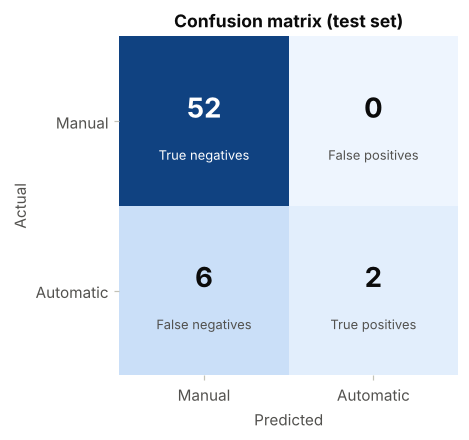

In [39]:
def plot_cm(cm, title, name):
    fig, ax = plt.subplots(figsize=(4.6, 4.0))
    ax.imshow(cm, cmap=SEQUENTIAL, vmin=0, vmax=cm.max())
    labels = [["True negatives", "False positives"], ["False negatives", "True positives"]]
    for i in range(2):
        for j in range(2):
            dark = cm[i, j] > cm.max() * 0.55
            ax.text(j, i - 0.08, f"{cm[i, j]}", ha="center", va="center", fontsize=18,
                    fontweight="bold", color="white" if dark else INK)
            ax.text(j, i + 0.2, labels[i][j], ha="center", va="center", fontsize=8.5,
                    color="white" if dark else INK2)
    ax.set_xticks([0, 1], ["Manual", "Automatic"]); ax.set_yticks([0, 1], ["Manual", "Automatic"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(title)
    save(fig, name)

plot_cm(cm, "Confusion matrix (test set)", "fig11_confusion_matrix")

In [40]:
# Which test vehicles were misclassified?
mis = df.loc[y2_test.index, ["Car_Name", "Year", "Present_Price", "Selling_Price", "Kms_Driven",
                             "Fuel_Type", "Seller_Type", "Transmission"]].copy()
mis["P(Automatic)"] = y2_proba.round(3)
mis[y2_pred != y2_test.values]

,Car_Name,Year,Present_Price,Selling_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,P(Automatic)
12,ciaz,2015,9.94,7.50,15000,Petrol,Dealer,Automatic,0.141
163,Activa 3g,2016,0.54,0.45,500,Petrol,Individual,Automatic,0.056
250,brio,2015,6.82,5.40,31427,Petrol,Dealer,Automatic,0.104
230,elantra,2015,14.79,11.45,12900,Petrol,Dealer,Automatic,0.268
48,ciaz,2017,9.29,7.75,37000,Petrol,Dealer,Automatic,0.148
78,fortuner,2012,30.61,14.50,89000,Diesel,Dealer,Automatic,0.417


**Interpretation.**
* **Confusion matrix:** 52 manual vehicles correctly identified, **0 false alarms**, 2 automatics caught and **6 automatics missed**.
* **Accuracy = 0.90** (54 of 60 correct), only about 3 points above the "always Manual" baseline (0.867).
* **Precision (Automatic) = 1.00.** *When the model predicts Automatic, how often is it correct?* Every time (2 of 2).
* **Recall (Automatic) = 0.25.** *Out of all actual automatics, how many did we catch?* Only 2 of 8.

The model is very **cautious**: it predicts Automatic only for clearly expensive vehicles. The vehicles it missed are mid-priced automatics (two Ciaz, a Brio, an Elantra), an Activa scooter and a 2012 Fortuner (probability 0.42, just under the 0.5 threshold). Their price, age and mileage look exactly like those of manual vehicles. The test set has only 8 automatics, so each one moves recall by 12.5 points.

### 10.1 Extra check — stability and the class-imbalance issue
The test set has only a handful of automatic cars, so one or two predictions swing precision and recall a lot.
We therefore (a) estimate the metrics with **stratified 5-fold cross-validation** on the training data, and
(b) try `class_weight="balanced"`, which gives the rare Automatic class more weight during training so the
model is pushed to catch more of them.

In [41]:
preprocess_p2 = ColumnTransformer([("num", StandardScaler(), NUMERIC_P2)], remainder="passthrough")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, cw in [("Default", None), ("Balanced class weights", "balanced")]:
    pipe = Pipeline([("prep", preprocess_p2), ("model", LogisticRegression(max_iter=1000, class_weight=cw))])
    res = cross_validate(pipe, X2_train, y2_train, cv=skf, scoring=("accuracy", "precision", "recall"))
    pipe.fit(X2_train, y2_train)
    p = pipe.predict(X2_test)
    rows.append({"model": name,
                 "CV accuracy": f"{res['test_accuracy'].mean():.3f} ± {res['test_accuracy'].std():.3f}",
                 "CV precision": f"{res['test_precision'].mean():.3f} ± {res['test_precision'].std():.3f}",
                 "CV recall": f"{res['test_recall'].mean():.3f} ± {res['test_recall'].std():.3f}",
                 "Test accuracy": round(accuracy_score(y2_test, p), 3),
                 "Test precision": round(precision_score(y2_test, p, zero_division=0), 3),
                 "Test recall": round(recall_score(y2_test, p), 3)})
    if cw == "balanced":
        cm_bal = confusion_matrix(y2_test, p, labels=[0, 1])
pd.DataFrame(rows).set_index("model")

,CV accuracy,CV precision,CV recall,Test accuracy,Test precision,Test recall
model,,,,,,
Default,0.891 ± 0.020,0.867 ± 0.267,0.224 ± 0.072,0.900,1.000,0.25
Balanced class weights,0.812 ± 0.051,0.350 ± 0.129,0.476 ± 0.140,0.783,0.308,0.50


In [42]:
print(pd.DataFrame(cm_bal, index=["Actual Manual", "Actual Automatic"],
                   columns=["Predicted Manual", "Predicted Automatic"]))

                  Predicted Manual  Predicted Automatic
Actual Manual                   43                    9
Actual Automatic                 4                    4


**Interpretation.**
* Cross-validation confirms the picture for the default model: accuracy 0.89 ± 0.02 and recall only 0.22 ± 0.07, while precision is high but **unstable** (0.87 ± 0.27).
* With **balanced class weights**, recall doubles (CV 0.48; on the test set 4 of 8 automatics are caught). The cost is lower precision (~0.3, with 9 manual vehicles falsely flagged) and accuracy falling to 0.78. This is the classic **precision/recall trade-off**.
* The better version depends on the business goal. A dealer hunting for automatics to stock would want higher recall. A listing website auto-filling the "transmission" field would want high precision.

## 11. Conclusion for Part 2

The available features predict transmission type only **moderately well**.
* Accuracy is 90 %, just above the 87 % you get by always guessing "Manual".
* The model is precise when it says "Automatic", but it **misses most automatics** (recall 25 %).
* Price is the only strong signal: expensive vehicles are usually automatic. Age, mileage and ownership carry little information.
* Mid-priced automatic versions of popular models cannot be told apart from their manual twins without information such as the model/variant name, engine type or body type.
* Re-weighting the classes (or lowering the decision threshold) can raise recall, but only by giving up precision.

---
# Appendix — figures used in the theoretical background

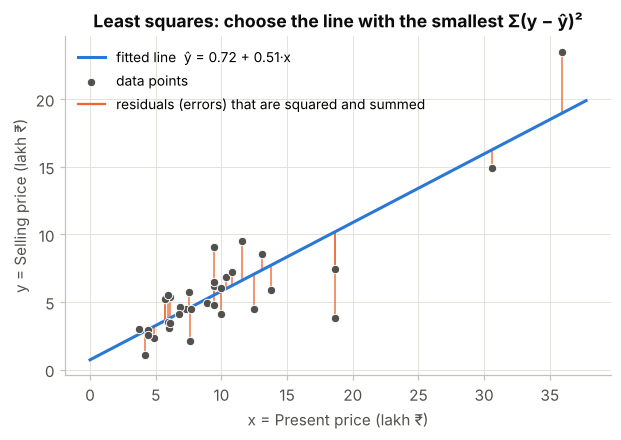

In [43]:
# (a) Linear regression idea: fit the line that minimises the sum of squared errors
cars = df[df["Seller_Type"] == "Dealer"].sample(35, random_state=RANDOM_STATE)
x, y = cars[["Present_Price"]], cars["Selling_Price"]
m = LinearRegression().fit(x, y)
xs = np.linspace(0, x.values.max() * 1.05, 50).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(6.4, 4.0))
for xi, yi, yh in zip(x.values.ravel(), y, m.predict(x)):
    ax.plot([xi, xi], [yi, yh], color=ORANGE, linewidth=1, alpha=0.9)
ax.plot(xs, m.predict(pd.DataFrame(xs, columns=["Present_Price"])), color=BLUE, linewidth=2,
        label=f"fitted line  ŷ = {m.intercept_:.2f} + {m.coef_[0]:.2f}·x")
ax.scatter(x, y, s=30, color=INK2, edgecolor="white", linewidth=0.6, zorder=3, label="data points")
ax.plot([], [], color=ORANGE, label="residuals (errors) that are squared and summed")
ax.set_xlabel("x = Present price (lakh ₹)"); ax.set_ylabel("y = Selling price (lakh ₹)")
ax.set_title("Least squares: choose the line with the smallest Σ(y − ŷ)²")
ax.legend(loc="upper left")
save(fig, "fig00a_least_squares_idea")

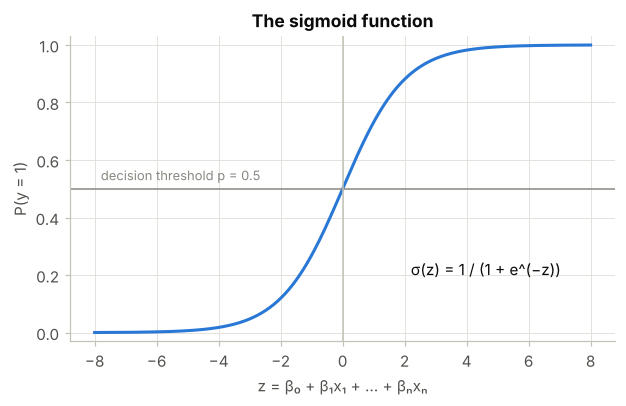

In [44]:
# (b) The sigmoid (logistic) function maps any real number to a probability in (0, 1)
z = np.linspace(-8, 8, 400)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(z, 1 / (1 + np.exp(-z)), color=BLUE, linewidth=2)
ax.axhline(0.5, color=MUTED, linewidth=1)
ax.axvline(0, color=AXIS, linewidth=1)
ax.text(-7.8, 0.53, "decision threshold p = 0.5", color=MUTED, fontsize=8.5)
ax.text(2.2, 0.2, "σ(z) = 1 / (1 + e^(−z))", color=INK, fontsize=10)
ax.set_xlabel("z = β₀ + β₁x₁ + … + βₙxₙ"); ax.set_ylabel("P(y = 1)")
ax.set_ylim(-0.03, 1.03)
ax.set_title("The sigmoid function")
save(fig, "fig00b_sigmoid")